# E-DAC capacity & gas capacity lowest Combo

This note book finds `E-DAC capacity` and `gas capacity` combos，filters `annual net CO2 capture >= 35.8 MtCO2/yr` ，and find its lowest cost


In [30]:
from __future__ import annotations

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import plotly.graph_objects as go
from IPython.display import display

import src.assumptions as A
import src.matplotlib_style  # noqa: F401
from src.data import renewable_capacity_factors
from src.demand_model import DemandMode, predicted_demand
from src.power_system_no_h2 import PowerSystemNoH2
from src.supply_model import daily_renewables_capacity
from src.units import Units as U

## paramets

`RENEWABLE_CAPACITY_GRID_GW`、`E_DAC_CAPACITY_GRID_GW` 和 `GAS_CAPACITY_GRID_GW` 控制三维搜索范围。网格越细，结果越精确，但运行时间越长。

In [31]:
TARGET_NET_CAPTURE_MT = 35.8
RENEWABLE_CAPACITY_GRID_GW = np.arange(180, 500, 10)

ENABLE_IMPORTS = False
CAPACITY_FACTORS_SOURCE = "era5_2024"
DEMAND_MODE = DemandMode.SEASONAL

# steps setting
E_DAC_CAPACITY_GRID_GW = np.round(np.arange(0.0, 8.01, 0.1), 3)
GAS_CAPACITY_GRID_GW = np.round(np.arange(0.0, 250.1, 1.0), 3)

# allow small tolerance for gas capacity to avoid numerical issues in optimization
GAS_CAPACITY_TOL_GW = 1e-9

In [32]:
demand_df = predicted_demand(mode=DEMAND_MODE, historical="era5", filter_ldz=True)
daily_cf = renewable_capacity_factors.get_renewable_capacity_factors(
    source=CAPACITY_FACTORS_SOURCE,
    resample="D",
)


def build_net_supply_df(ren_gw: int) -> pd.DataFrame:
    supply = daily_renewables_capacity(ren_gw * U.GW, daily_cf)
    common_idx = supply.index.intersection(demand_df.index)
    supply = supply.reindex(common_idx)
    demand = demand_df.reindex(common_idx)
    net_supply_df = (supply - demand["demand"]).to_frame(name=f"S-D(TWh),Ren={ren_gw}GW")
    net_supply_df = net_supply_df.reset_index()
    net_supply_df = net_supply_df.rename(columns={net_supply_df.columns[0]: "index"})
    return net_supply_df


net_supply_by_renewable_gw = {
    int(ren_gw): build_net_supply_df(int(ren_gw))
    for ren_gw in RENEWABLE_CAPACITY_GRID_GW
}

## evaluation

one simulation per value

In [33]:
def make_no_h2_system(*, renewable_capacity_gw: int, e_dac_capacity_gw: float, gas_capacity_gw: float) -> PowerSystemNoH2:
    return PowerSystemNoH2(
        renewable_capacity=renewable_capacity_gw * U.GW,
        dac_capacity=e_dac_capacity_gw * U.GW,
        gas_ccs_capacity=gas_capacity_gw * U.GW,
        enable_imports=ENABLE_IMPORTS,
        capacity_factors_source=CAPACITY_FACTORS_SOURCE,
    )


def peak_gas_capacity_gw(sim_df: pd.DataFrame, renewable_capacity_gw: int) -> float:
    gas_col = f"gas_ccs_energy (TWh),RC={renewable_capacity_gw}GW"
    peak_gas_twh = sim_df[gas_col].max()
    if hasattr(peak_gas_twh, "units"):
        return (peak_gas_twh / A.HoursPerDay).to(U.GW).magnitude
    return (peak_gas_twh * U.TWh / A.HoursPerDay).to(U.GW).magnitude


def total_cost_gbp_per_year(system: PowerSystemNoH2, sim_df: pd.DataFrame, analysis: dict) -> float:
    power_system_cost = system.calculate_power_system_cost(sim_df).to(U.GBP).magnitude
    dac_cost = analysis["annual_dac_total_cost"].to(U.GBP).magnitude
    return power_system_cost + dac_cost


def evaluate_capacity_pair(renewable_capacity_gw: int, e_dac_capacity_gw: float) -> list[dict[str, float | bool | str]]:
    net_supply_df = net_supply_by_renewable_gw[renewable_capacity_gw]
    simulation_system = make_no_h2_system(
        renewable_capacity_gw=renewable_capacity_gw,
        e_dac_capacity_gw=e_dac_capacity_gw,
        gas_capacity_gw=float(GAS_CAPACITY_GRID_GW.max()),
    )
    sim_df = simulation_system.run_simulation(net_supply_df)
    analysis = simulation_system.analyze_simulation_results(sim_df)
    if sim_df is None or analysis is None:
        return [
            {
                "renewable_capacity_gw": renewable_capacity_gw,
                "e_dac_capacity_gw": e_dac_capacity_gw,
                "gas_capacity_gw": np.nan,
                "status": "simulation_failed",
                "target_feasible": False,
                "gas_capacity_feasible": False,
                "annual_net_capture_mt": np.nan,
                "total_cost_gbp_yr": np.nan,
            }
        ]

    implied_peak_gas_gw = peak_gas_capacity_gw(sim_df, renewable_capacity_gw)
    annual_net_capture_mt = analysis["annual_net_capture"].to(U.Mt).magnitude
    annual_grid_dac_capture_mt = analysis["annual_co2_removals"].to(U.Mt).magnitude
    annual_gas_dac_capture_mt = analysis["annual_gas_dac_capture"].to(U.Mt).magnitude
    annual_gas_emissions_mt = analysis["annual_gas_emissions"].to(U.Mt).magnitude
    annual_gas_twh = analysis["annual_gas_ccs_energy"].to(U.TWh).magnitude
    curtailed_twh = analysis["curtailed_energy"].to(U.TWh).magnitude

    rows: list[dict[str, float | bool | str]] = []
    for gas_capacity_gw in GAS_CAPACITY_GRID_GW:
        gas_capacity_gw = float(gas_capacity_gw)
        cost_system = make_no_h2_system(
            renewable_capacity_gw=renewable_capacity_gw,
            e_dac_capacity_gw=e_dac_capacity_gw,
            gas_capacity_gw=gas_capacity_gw,
        )
        total_cost = total_cost_gbp_per_year(cost_system, sim_df, analysis)
        target_feasible = annual_net_capture_mt >= TARGET_NET_CAPTURE_MT
        gas_capacity_feasible = gas_capacity_gw + GAS_CAPACITY_TOL_GW >= implied_peak_gas_gw

        rows.append(
            {
                "renewable_capacity_gw": renewable_capacity_gw,
                "e_dac_capacity_gw": e_dac_capacity_gw,
                "gas_capacity_gw": gas_capacity_gw,
                "status": "ok",
                "target_feasible": target_feasible,
                "gas_capacity_feasible": gas_capacity_feasible,
                "physical_and_target_feasible": target_feasible and gas_capacity_feasible,
                "annual_net_capture_mt": annual_net_capture_mt,
                "target_surplus_mt": annual_net_capture_mt - TARGET_NET_CAPTURE_MT,
                "implied_peak_gas_capacity_gw": implied_peak_gas_gw,
                "annual_grid_dac_capture_mt": annual_grid_dac_capture_mt,
                "annual_gas_dac_capture_mt": annual_gas_dac_capture_mt,
                "annual_gas_emissions_mt": annual_gas_emissions_mt,
                "annual_gas_twh": annual_gas_twh,
                "curtailed_twh": curtailed_twh,
                "total_cost_gbp_yr": total_cost,
                "total_cost_gbp_per_mwh": (total_cost * U.GBP / A.EnergyDemand2050).to(U.GBP / U.MWh).magnitude,
            }
        )
    return rows

## Perform 3d net search

In [34]:
rows: list[dict[str, float | bool | str]] = []

total_runs = len(RENEWABLE_CAPACITY_GRID_GW) * len(E_DAC_CAPACITY_GRID_GW)
run_count = 0

for renewable_capacity_gw in RENEWABLE_CAPACITY_GRID_GW:
    renewable_capacity_gw = int(renewable_capacity_gw)
    for e_dac_capacity_gw in E_DAC_CAPACITY_GRID_GW:
        run_count += 1
        rows.extend(evaluate_capacity_pair(renewable_capacity_gw, float(e_dac_capacity_gw)))
        if run_count % 25 == 0 or run_count == total_runs:
            print(f"Finished {run_count}/{total_runs} renewable/E-DAC simulations")

results = pd.DataFrame(rows)
feasible = results[results["physical_and_target_feasible"]].copy()

print(f"Total combinations: {len(results):,}")
print(f"Feasible combinations: {len(feasible):,}")

Finished 25/2592 renewable/E-DAC simulations
Finished 50/2592 renewable/E-DAC simulations
Finished 75/2592 renewable/E-DAC simulations
Finished 100/2592 renewable/E-DAC simulations
Finished 125/2592 renewable/E-DAC simulations
Finished 150/2592 renewable/E-DAC simulations
Finished 175/2592 renewable/E-DAC simulations
Finished 200/2592 renewable/E-DAC simulations
Finished 225/2592 renewable/E-DAC simulations
Finished 250/2592 renewable/E-DAC simulations
Finished 275/2592 renewable/E-DAC simulations
Finished 300/2592 renewable/E-DAC simulations
Finished 325/2592 renewable/E-DAC simulations
Finished 350/2592 renewable/E-DAC simulations
Finished 375/2592 renewable/E-DAC simulations
Finished 400/2592 renewable/E-DAC simulations
Finished 425/2592 renewable/E-DAC simulations
Finished 450/2592 renewable/E-DAC simulations
Finished 475/2592 renewable/E-DAC simulations
Finished 500/2592 renewable/E-DAC simulations
Finished 525/2592 renewable/E-DAC simulations
Finished 550/2592 renewable/E-DAC sim

## Lowest Cost Combo

In [36]:
summary_cols = [
    "renewable_capacity_gw",
    "e_dac_capacity_gw",
    "gas_capacity_gw",
    "implied_peak_gas_capacity_gw",
    "annual_net_capture_mt",
    "target_surplus_mt",
    "annual_grid_dac_capture_mt",
    "annual_gas_dac_capture_mt",
    "annual_gas_emissions_mt",
    "annual_gas_twh",
    "curtailed_twh",
    "total_cost_gbp_yr",
    "total_cost_gbp_per_mwh",
]

if feasible.empty:
    print("No feasible combination found. Increase RENEWABLE_CAPACITY_GRID_GW, E_DAC_CAPACITY_GRID_GW, or GAS_CAPACITY_GRID_GW range.")
else:
    best = feasible.sort_values("total_cost_gbp_yr").iloc[0]
    display(feasible.sort_values("total_cost_gbp_yr")[summary_cols].head(20).round(3))
    best_summary = pd.to_numeric(best[summary_cols]).rename("best_combination")
    display(best_summary.round(3))

    print(
        "Best feasible combination:\n"
        f"- Renewable capacity: {best['renewable_capacity_gw']:.0f} GW\n"
        f"- E-DAC capacity: {best['e_dac_capacity_gw']:.3f} GW\n"
        f"- Gas capacity: {best['gas_capacity_gw']:.3f} GW\n"
        f"- Implied peak gas capacity: {best['implied_peak_gas_capacity_gw']:.3f} GW\n"
        f"- Net capture: {best['annual_net_capture_mt']:.3f} MtCO2/yr\n"
        f"- Total annual cost: {best['total_cost_gbp_yr']:.3e} GBP/yr\n"
        f"- Average cost: {best['total_cost_gbp_per_mwh']:.3f} GBP/MWh"
    )

,renewable_capacity_gw,e_dac_capacity_gw,gas_capacity_gw,implied_peak_gas_capacity_gw,annual_net_capture_mt,target_surplus_mt,annual_grid_dac_capture_mt,annual_gas_dac_capture_mt,annual_gas_emissions_mt,annual_gas_twh,curtailed_twh,total_cost_gbp_yr,total_cost_gbp_per_mwh
291746,320,2.8,84.0,83.213,36.883,1.083,34.473,5.042,2.632,8.533,438.751,4.376583e+10,63.245
312076,330,2.8,83.0,82.142,36.977,1.177,34.884,4.379,2.286,7.411,470.630,4.376733e+10,63.248
291997,320,2.9,84.0,83.213,38.104,2.304,35.694,5.042,2.632,8.533,437.973,4.381006e+10,63.309
312327,330,2.9,83.0,82.142,38.214,2.414,36.121,4.379,2.286,7.411,469.841,4.381216e+10,63.312
312077,330,2.8,84.0,82.142,36.977,1.177,34.884,4.379,2.286,7.411,470.630,4.381987e+10,63.324
291747,320,2.8,85.0,83.213,36.883,1.083,34.473,5.042,2.632,8.533,438.751,4.382593e+10,63.332
292248,320,3.0,84.0,83.213,39.324,3.524,36.914,5.042,2.632,8.533,437.195,4.385427e+10,63.373
312578,330,3.0,83.0,82.142,39.451,3.651,37.358,4.379,2.286,7.411,469.053,4.385697e+10,63.377
312328,330,2.9,84.0,82.142,38.214,2.414,36.121,4.379,2.286,7.411,469.841,4.386471e+10,63.388
291998,320,2.9,85.0,83.213,38.104,2.304,35.694,5.042,2.632,8.533,437.973,4.387015e+10,63.396


renewable_capacity_gw           3.200000e+02
e_dac_capacity_gw               2.800000e+00
gas_capacity_gw                 8.400000e+01
implied_peak_gas_capacity_gw    8.321300e+01
annual_net_capture_mt           3.688300e+01
target_surplus_mt               1.083000e+00
annual_grid_dac_capture_mt      3.447300e+01
annual_gas_dac_capture_mt       5.042000e+00
annual_gas_emissions_mt         2.632000e+00
annual_gas_twh                  8.533000e+00
curtailed_twh                   4.387510e+02
total_cost_gbp_yr               4.376583e+10
total_cost_gbp_per_mwh          6.324500e+01
Name: best_combination, dtype: float64

Best feasible combination:
- Renewable capacity: 320 GW
- E-DAC capacity: 2.800 GW
- Gas capacity: 84.000 GW
- Implied peak gas capacity: 83.213 GW
- Net capture: 36.883 MtCO2/yr
- Total annual cost: 4.377e+10 GBP/yr
- Average cost: 63.245 GBP/MWh


## visualisation

In [37]:
if feasible.empty:
    print("No feasible combinations to plot.")
else:
    # For each renewable/E-DAC pair, keep the cheapest feasible gas capacity.
    frontier = (
        feasible.sort_values(["renewable_capacity_gw", "e_dac_capacity_gw", "total_cost_gbp_yr"])
        .groupby(["renewable_capacity_gw", "e_dac_capacity_gw"], as_index=False)
        .first()
        .sort_values("total_cost_gbp_yr")
    )
    frontier["total_cost_billion_gbp_yr"] = frontier["total_cost_gbp_yr"] / 1e9

    fig = go.Figure()
    fig.add_trace(
        go.Scatter3d(
            x=frontier["renewable_capacity_gw"],
            y=frontier["e_dac_capacity_gw"],
            z=frontier["gas_capacity_gw"],
            mode="markers",
            name="Feasible frontier",
            marker={
                "size": 4,
                "color": frontier["total_cost_billion_gbp_yr"],
                "colorscale": "Viridis",
                "opacity": 0.85,
                "colorbar": {"title": "Cost<br>(bn GBP/yr)"},
            },
            customdata=frontier[
                [
                    "annual_net_capture_mt",
                    "annual_grid_dac_capture_mt",
                    "annual_gas_dac_capture_mt",
                    "annual_gas_emissions_mt",
                    "total_cost_billion_gbp_yr",
                    "total_cost_gbp_per_mwh",
                ]
            ],
            hovertemplate=(
                "Renewables: %{x:.0f} GW<br>"
                "E-DAC: %{y:.2f} GW<br>"
                "Gas: %{z:.1f} GW<br>"
                "Net capture: %{customdata[0]:.2f} MtCO2/yr<br>"
                "Grid E-DAC capture: %{customdata[1]:.2f} MtCO2/yr<br>"
                "Gas DAC capture: %{customdata[2]:.2f} MtCO2/yr<br>"
                "Gas emissions: %{customdata[3]:.2f} MtCO2/yr<br>"
                "Cost: %{customdata[4]:.2f} bn GBP/yr<br>"
                "Average cost: %{customdata[5]:.2f} GBP/MWh"
                "<extra></extra>"
            ),
        )
    )
    fig.add_trace(
        go.Scatter3d(
            x=[best["renewable_capacity_gw"]],
            y=[best["e_dac_capacity_gw"]],
            z=[best["gas_capacity_gw"]],
            mode="markers",
            name="Minimum cost",
            marker={"size": 9, "color": "red", "symbol": "diamond"},
            hovertemplate=(
                "Minimum cost<br>"
                f"Renewables: {best['renewable_capacity_gw']:.0f} GW<br>"
                f"E-DAC: {best['e_dac_capacity_gw']:.2f} GW<br>"
                f"Gas: {best['gas_capacity_gw']:.1f} GW<br>"
                f"Net capture: {best['annual_net_capture_mt']:.2f} MtCO2/yr<br>"
                f"Cost: {best['total_cost_gbp_yr'] / 1e9:.2f} bn GBP/yr"
                "<extra></extra>"
            ),
        )
    )
    fig.update_layout(
        title=(
            "3D minimum-cost frontier<br>"
            f"Net capture >= {TARGET_NET_CAPTURE_MT} MtCO2/yr, no-H2 mode"
        ),
        scene={
            "xaxis_title": "Renewable capacity (GW)",
            "yaxis_title": "E-DAC capacity (GW)",
            "zaxis_title": "Gas capacity (GW)",
            "camera": {"eye": {"x": 1.7, "y": -1.7, "z": 1.1}},
        },
        width=950,
        height=700,
        legend={"x": 0.02, "y": 0.98},
        margin={"l": 0, "r": 0, "b": 0, "t": 70},
    )
    fig.show()

    display(
        frontier[
            [
                "renewable_capacity_gw",
                "e_dac_capacity_gw",
                "gas_capacity_gw",
                "annual_net_capture_mt",
                "annual_grid_dac_capture_mt",
                "annual_gas_dac_capture_mt",
                "annual_gas_emissions_mt",
                "total_cost_billion_gbp_yr",
                "total_cost_gbp_per_mwh",
            ]
        ].head(30).round(3)
    )

,renewable_capacity_gw,e_dac_capacity_gw,gas_capacity_gw,annual_net_capture_mt,annual_grid_dac_capture_mt,annual_gas_dac_capture_mt,annual_gas_emissions_mt,total_cost_billion_gbp_yr,total_cost_gbp_per_mwh
753,320,2.8,84.0,36.883,34.473,5.042,2.632,43.766,63.245
806,330,2.8,83.0,36.977,34.884,4.379,2.286,43.767,63.248
754,320,2.9,84.0,38.104,35.694,5.042,2.632,43.810,63.309
807,330,2.9,83.0,38.214,36.121,4.379,2.286,43.812,63.312
755,320,3.0,84.0,39.324,36.914,5.042,2.632,43.854,63.373
808,330,3.0,83.0,39.451,37.358,4.379,2.286,43.857,63.377
700,310,2.8,85.0,36.760,33.975,5.826,3.041,43.890,63.425
756,320,3.1,84.0,40.543,38.133,5.042,2.632,43.898,63.437
809,330,3.1,83.0,40.687,38.594,4.379,2.286,43.902,63.442
859,340,2.7,82.0,35.865,34.037,3.825,1.997,43.931,63.485


In [ ]:
FIXED_E_DAC_CAPACITY_VALUES_GW = [2.6, 2.8, 3.0, 3.2]

fixed_edac_rows: list[dict[str, float | str]] = []

for fixed_e_dac_capacity_gw in FIXED_E_DAC_CAPACITY_VALUES_GW:
    for renewable_capacity_gw in RENEWABLE_CAPACITY_GRID_GW:
        renewable_capacity_gw = int(renewable_capacity_gw)
        net_supply_df = net_supply_by_renewable_gw[renewable_capacity_gw]
        system = make_no_h2_system(
            renewable_capacity_gw=renewable_capacity_gw,
            e_dac_capacity_gw=fixed_e_dac_capacity_gw,
            gas_capacity_gw=float(GAS_CAPACITY_GRID_GW.max()),
        )
        sim_df = system.run_simulation(net_supply_df)
        analysis = system.analyze_simulation_results(sim_df)

        if sim_df is None or analysis is None:
            fixed_edac_rows.append(
                {
                    "renewable_capacity_gw": renewable_capacity_gw,
                    "fixed_e_dac_capacity_gw": fixed_e_dac_capacity_gw,
                    "status": "simulation_failed",
                    "annual_net_capture_mt": np.nan,
                    "implied_peak_gas_capacity_gw": np.nan,
                }
            )
            continue

        fixed_edac_rows.append(
            {
                "renewable_capacity_gw": renewable_capacity_gw,
                "fixed_e_dac_capacity_gw": fixed_e_dac_capacity_gw,
                "status": "ok",
                "annual_net_capture_mt": analysis["annual_net_capture"].to(U.Mt).magnitude,
                "implied_peak_gas_capacity_gw": peak_gas_capacity_gw(sim_df, renewable_capacity_gw),
            }
        )

fixed_edac_check = pd.DataFrame(fixed_edac_rows)
print(f"Computed {len(fixed_edac_check):,} fixed E-DAC / renewable capacity combinations")

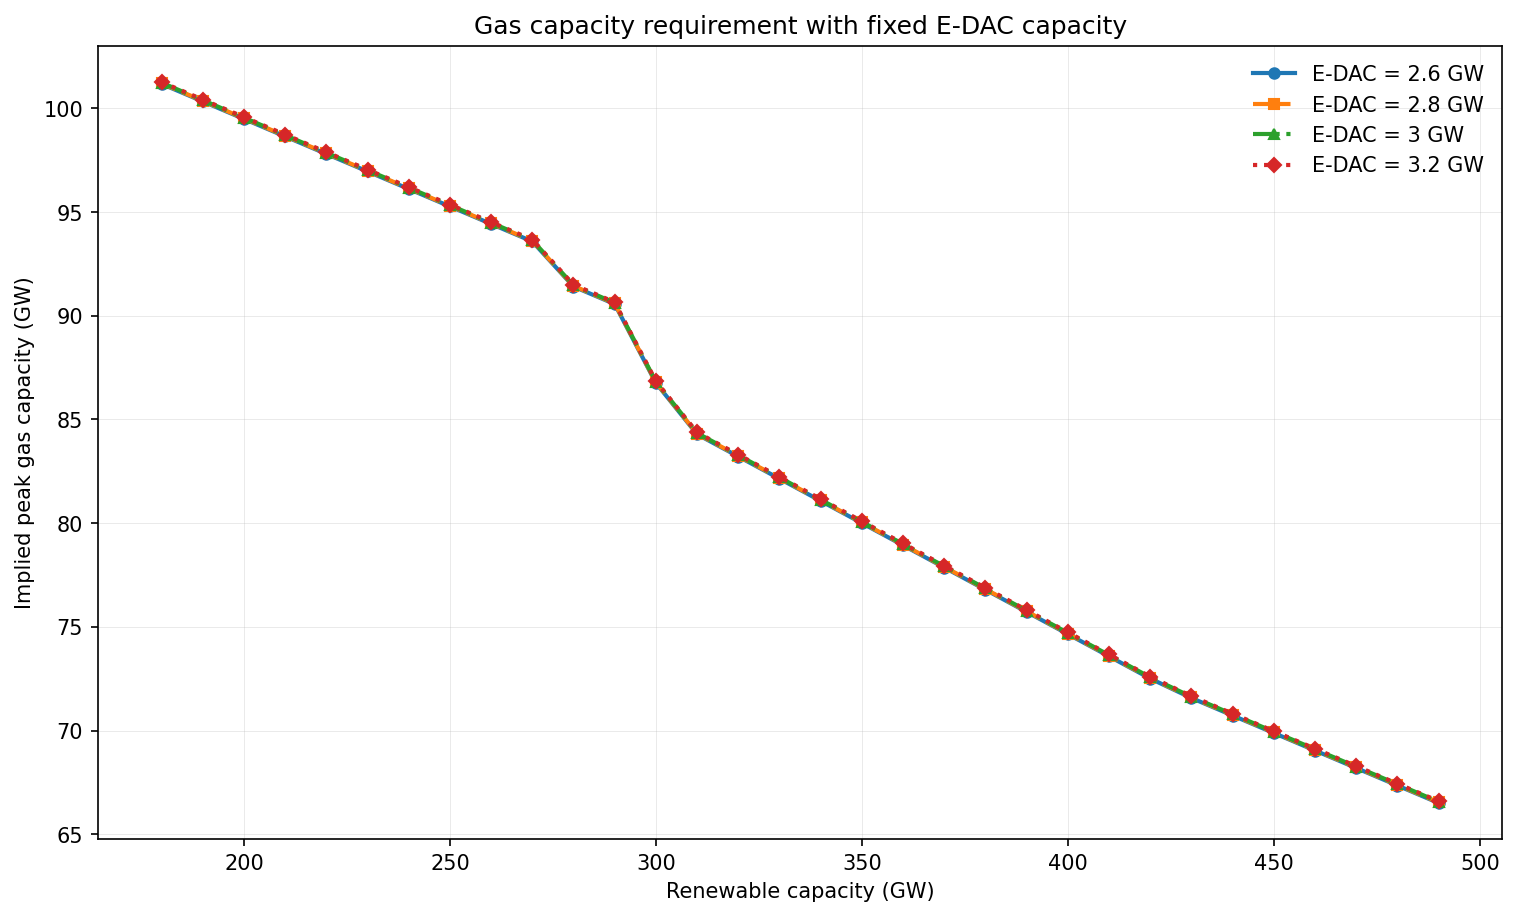

In [40]:
fig, ax = plt.subplots(figsize=(10, 6))

styles = {
    2.6: {"marker": "o", "linestyle": "-", "color": "tab:blue"},
    2.8: {"marker": "s", "linestyle": "--", "color": "tab:orange"},
    3.0: {"marker": "^", "linestyle": "-.", "color": "tab:green"},
    3.2: {"marker": "D", "linestyle": ":", "color": "tab:red"},
}

ok_df = fixed_edac_check[fixed_edac_check["status"] == "ok"].copy()

for i, fixed_e_dac_gw in enumerate(FIXED_E_DAC_CAPACITY_VALUES_GW):
    group = ok_df[
        ok_df["fixed_e_dac_capacity_gw"] == fixed_e_dac_gw
    ].sort_values("renewable_capacity_gw")

    if group.empty:
        print(f"No data for E-DAC = {fixed_e_dac_gw:g} GW")
        continue

    # Tiny visual offset only, so overlapping lines are visible.
    y_offset = i * 0.03

    style = styles.get(
        fixed_e_dac_gw,
        {"marker": "o", "linestyle": "-", "color": None},
    )

    ax.plot(
        group["renewable_capacity_gw"],
        group["implied_peak_gas_capacity_gw"] + y_offset,
        marker=style["marker"],
        linestyle=style["linestyle"],
        color=style["color"],
        linewidth=2,
        markersize=5,
        label=f"E-DAC = {fixed_e_dac_gw:g} GW",
    )

ax.set_xlabel("Renewable capacity (GW)")
ax.set_ylabel("Implied peak gas capacity (GW)")
ax.set_title("Gas capacity requirement with fixed E-DAC capacity")
ax.grid(True, alpha=0.3)
ax.legend(loc="best")

plt.show()

## Why gas capacity does not fall in a straight line

Gas capacity does not decrease in a perfectly straight line when renewable capacity increases.

The reason:

**Gas capacity is set by the worst day, not by the average year.**

The model asks:

> What is the biggest electricity shortage on any day?

That biggest shortage determines the gas capacity needed.

More renewables usually reduce the need for gas. But renewables do not produce the same amount every day.

Some days are windy and sunny.  
Some days are not windy and not sunny.

On a windy or sunny day, adding more renewable capacity helps a lot.

On a low-wind, low-sun day, adding more renewable capacity helps much less.

So the worst day can change as renewable capacity increases.

For example:

```text
At 200 GW renewables, the worst day might be Day A.
At 260 GW renewables, the worst day might still be Day A.
At 290 GW renewables, Day A may no longer be the worst. Now Day B is the worst.
At 310 GW renewables, Day C may become the worst.

low renewable：
same worst day -> same slope -> looks linear

high renewable there is a around 270GW worst day：
worst day changes -> slope changes -> non-linear

That original bad day is no longer the only problem. Because the reneable covers it
the second worst day becomes the new bottleneck.
Then the line changes shape.

,renewable_capacity_gw,e_dac_capacity_gw,gas_capacity_gw,annual_net_capture_mt,annual_grid_dac_capture_mt,annual_gas_dac_capture_mt,annual_gas_emissions_mt,total_cost_billion_gbp_yr,total_cost_gbp_per_mwh
0,180,2.2,102.0,36.131,12.394,49.660,25.922,77.000,111.271
1,190,2.5,101.0,36.187,16.462,41.266,21.541,70.274,101.553
2,200,2.7,100.0,36.499,20.055,34.401,17.958,64.663,93.443
3,210,2.7,99.0,35.845,22.108,28.737,15.001,60.033,86.752
4,220,2.8,98.0,36.399,24.878,24.102,12.581,56.558,81.732
5,230,2.8,97.0,36.263,26.543,20.335,10.615,53.602,77.460
6,240,2.8,97.0,36.209,27.980,17.217,8.987,51.352,74.208
7,250,2.8,96.0,36.268,29.283,14.612,7.627,49.380,71.358
8,260,2.8,95.0,36.246,30.303,12.433,6.490,47.779,69.045
9,270,2.8,94.0,36.316,31.234,10.632,5.550,46.612,67.358


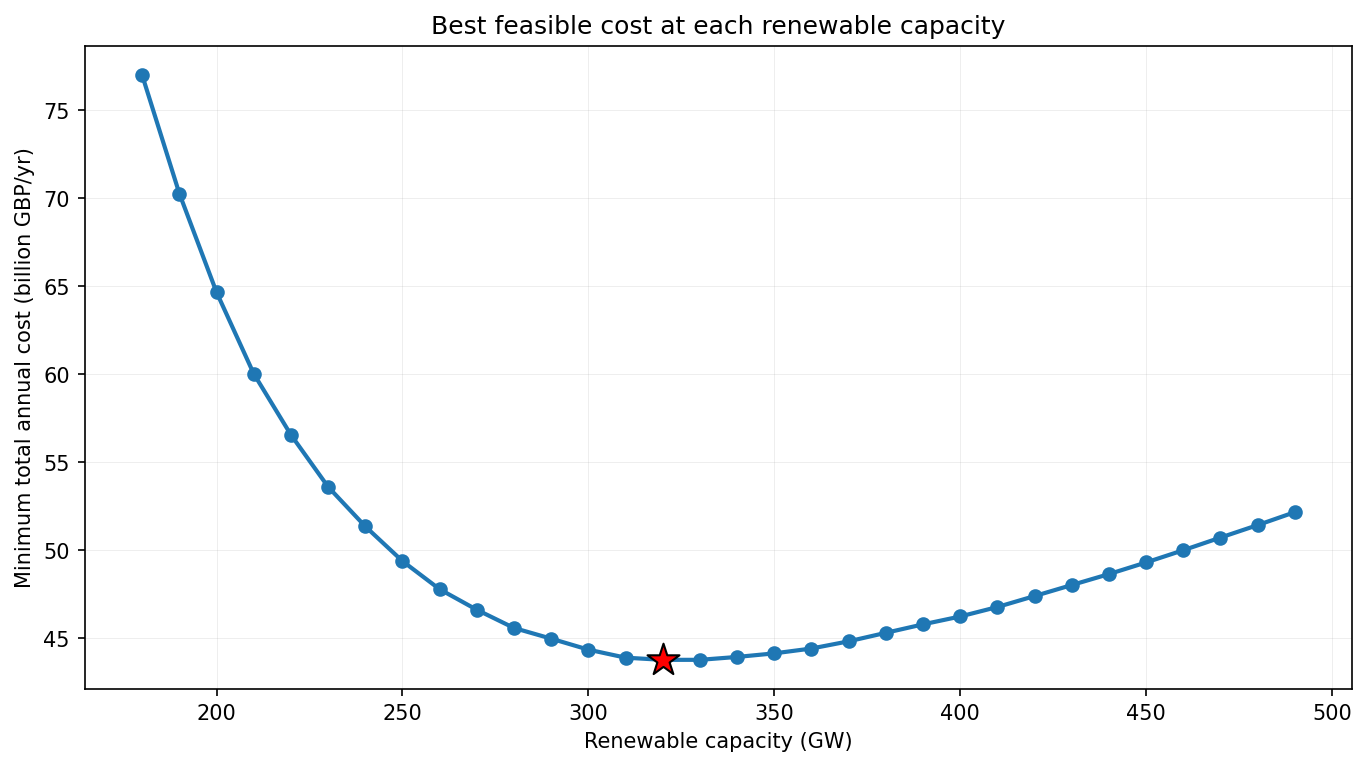

In [39]:
if feasible.empty:
    print("No feasible combinations to summarize.")
else:
    best_by_renewable = (
        feasible.sort_values(["renewable_capacity_gw", "total_cost_gbp_yr"])
        .groupby("renewable_capacity_gw", as_index=False)
        .first()
        .sort_values("renewable_capacity_gw")
    )
    best_by_renewable["total_cost_billion_gbp_yr"] = best_by_renewable["total_cost_gbp_yr"] / 1e9

    display(
        best_by_renewable[
            [
                "renewable_capacity_gw",
                "e_dac_capacity_gw",
                "gas_capacity_gw",
                "annual_net_capture_mt",
                "annual_grid_dac_capture_mt",
                "annual_gas_dac_capture_mt",
                "annual_gas_emissions_mt",
                "total_cost_billion_gbp_yr",
                "total_cost_gbp_per_mwh",
            ]
        ].round(3)
    )

    fig, ax1 = plt.subplots(figsize=(9, 5))
    ax1.plot(best_by_renewable["renewable_capacity_gw"], best_by_renewable["total_cost_billion_gbp_yr"], marker="o", linewidth=2)
    ax1.scatter(best["renewable_capacity_gw"], best["total_cost_gbp_yr"] / 1e9, marker="*", s=260, color="red", edgecolor="black", zorder=5)
    ax1.set_xlabel("Renewable capacity (GW)")
    ax1.set_ylabel("Minimum total annual cost (billion GBP/yr)")
    ax1.set_title("Best feasible cost at each renewable capacity")
    ax1.grid(True, alpha=0.25)
    plt.show()